<a href="https://colab.research.google.com/github/AI4Finance-Foundation/FinRL-Tutorials/blob/master/2-Advance/FinRL_Ensemble_StockTrading_ICAIF_2020.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Deep Reinforcement Learning for Stock Trading from Scratch: Multiple Stock Trading Using Ensemble Strategy

Tutorials to use OpenAI DRL to trade multiple stocks using ensemble strategy in one Jupyter Notebook | Presented at ICAIF 2020

* This notebook is the reimplementation of our paper: Deep Reinforcement Learning for Automated Stock Trading: An Ensemble Strategy, using FinRL.
* Check out medium blog for detailed explanations: https://medium.com/@ai4finance/deep-reinforcement-learning-for-automated-stock-trading-f1dad0126a02
* Please report any issues to our Github: https://github.com/AI4Finance-LLC/FinRL-Library/issues
* **Pytorch Version**



<a id='1'></a>
# Part 2. Getting Started- Load Python Packages


<a id='1.3'></a>
## 2.3. Import Packages


In [ ]:
import warnings
warnings.filterwarnings("ignore")


In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
# matplotlib.use('Agg')
import datetime

%matplotlib inline
from finrl.config_tickers import DOW_30_TICKER
from finrl.meta.preprocessor.yahoodownloader import YahooDownloader
from finrl.meta.preprocessor.preprocessors import FeatureEngineer, data_split
from finrl.meta.env_stock_trading.env_stocktrading import StockTradingEnv
from finrl.agents.stablebaselines3.models import DRLAgent,DRLEnsembleAgent

from pprint import pprint

import sys
sys.path.append("../FinRL-Library")

import itertools


from pathlib import Path

import os

PROJECT_ROOT = Path(os.environ.get("RGPPO_ROOT", str(Path.cwd())))
while not (PROJECT_ROOT / "data" / "new_version_2026").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.ensemble.ensemble_audit import AuditConfig, set_reproducible_seed, audit_ensemble_run
from finrl.plot import backtest_stats, backtest_plot, get_daily_return, get_baseline


<a id='1.4'></a>
## 2.4. Create Folders


In [ ]:
import os
from finrl.main import check_and_make_directories
from finrl.config import (
    DATA_SAVE_DIR,
    TRAINED_MODEL_DIR,
    TENSORBOARD_LOG_DIR,
    RESULTS_DIR,
    INDICATORS,
    TRAIN_START_DATE,
    TRAIN_END_DATE,
    TEST_START_DATE,
    TEST_END_DATE,
    TRADE_START_DATE,
    TRADE_END_DATE,
)

# check_and_make_directories(...) is handled per run by audit_ensemble_run

<a id='2'></a>
# Part 3. Download Data
Yahoo Finance is a website that provides stock data, financial news, financial reports, etc. All the data provided by Yahoo Finance is free.
* FinRL uses a class **YahooDownloader** to fetch data from Yahoo Finance API
* Call Limit: Using the Public API (without authentication), you are limited to 2,000 requests per hour per IP (or up to a total of 48,000 requests a day).


df.tail()


df.shape


df.sort_values(['date','tic']).head()


len(df.tic.unique())


df.tic.value_counts()


In [4]:
# TRAIN_START_DATE = '2009-04-01'
# TRAIN_END_DATE = '2021-01-01'
# TEST_START_DATE = '2021-01-01'
# TEST_END_DATE = '2022-06-01'

# TRAIN_START_DATE = '2010-01-01'
# TRAIN_END_DATE = '2021-10-01'
# TEST_START_DATE = '2021-10-01'
# TEST_END_DATE = '2023-03-01'

TRAIN_START_DATE = '2013-04-01'
TRAIN_END_DATE = '2024-12-31'
TEST_START_DATE = '2025-01-01'
TEST_END_DATE = '2026-06-01'

# TRAIN_START_DATE = '2010-01-04'



# df = YahooDownloader(start_date = TRAIN_START_DATE,
#                      end_date = TEST_END_DATE,
#                      ticker_list = DOW_30_TICKER).fetch_data()
PROJECT_ROOT = Path(os.environ.get("RGPPO_ROOT", str(Path.cwd())))
while not (PROJECT_ROOT / "data" / "new_version_2026").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_FILE = PROJECT_ROOT / "data/new_version_2026/data_30_20100101_20260601.csv"
DJI_FILE = PROJECT_ROOT / "data/DJI_2025_2026.csv"
NOTEBOOK_FILE = Path(os.environ.get("RGPPO_NOTEBOOK", str(PROJECT_ROOT / "ultimate_experiment" / "0101 AUST_ensemble + original" / "AUST_seed_0.ipynb")))

df = pd.read_csv(DATA_FILE)
df.head()


,date,close,high,low,open,volume,tic,day
0,2010-01-04,6.406482,6.421151,6.357688,6.389120,493729600,AAPL,0
1,2010-01-04,38.748535,38.849231,37.969805,38.016797,5277400,AMGN,0
2,2010-01-04,6.695000,6.830500,6.657000,6.812500,151998000,AMZN,0
3,2010-01-04,32.380951,32.523389,31.961551,32.293908,6894300,AXP,0
4,2010-01-04,43.777561,43.941200,42.702213,43.419113,6186700,BA,0


# Part 4: Preprocess Data
Data preprocessing is a crucial step for training a high quality machine learning model. We need to check for missing data and do feature engineering in order to convert the data into a model-ready state.
* Add technical indicators. In practical trading, various information needs to be taken into account, for example the historical stock prices, current holding shares, technical indicators, etc. In this article, we demonstrate two trend-following technical indicators: MACD and RSI.
* Add turbulence index. Risk-aversion reflects whether an investor will choose to preserve the capital. It also influences one's trading strategy when facing different market volatility level. To control the risk in a worst-case scenario, such as financial crisis of 2007–2008, FinRL employs the financial turbulence index that measures extreme asset price fluctuation.


In [ ]:
fe = FeatureEngineer(use_technical_indicator=True,
                     tech_indicator_list = INDICATORS,
                     use_turbulence=True,
                     user_defined_feature = False)

processed = fe.preprocess_data(df)
processed = processed.copy()
processed = processed.fillna(0)
processed = processed.replace(np.inf,0)


Successfully added technical indicators


Successfully added turbulence index


In [6]:
processed.sample(5)


,date,close,high,low,open,volume,tic,day,macd,boll_ub,boll_lb,rsi_30,cci_30,dx_30,close_30_sma,close_60_sma,turbulence
56295,2017-06-16,67.806274,68.419976,67.680384,68.333428,16936600,JPM,4,0.145510,69.431259,64.251262,50.727113,43.043894,1.882096,67.261018,67.708613,77.603964
10870,2011-06-10,103.054932,104.063343,100.477047,101.000208,7556800,GS,4,-2.845218,107.967367,99.201554,38.039834,-68.515034,25.302819,106.777308,112.928252,29.176657
45828,2016-01-28,87.724922,88.034563,86.474427,87.034173,3668610,MMM,3,-1.098194,90.244084,79.497532,49.875112,26.872163,10.021333,86.289818,89.927522,112.634169
9436,2011-04-01,21.202150,21.284159,21.006593,21.098063,18720200,KO,4,0.224634,21.228836,19.455051,63.210997,200.494127,40.396316,20.288144,20.017336,19.298672
25380,2013-05-15,13.113523,13.485050,12.915070,13.428786,741613600,AAPL,2,0.178990,14.682926,11.627804,46.610200,11.737619,14.931740,13.076547,13.247082,30.813548


<a id='4'></a>
# Part 5. Design Environment
Considering the stochastic and interactive nature of the automated stock trading tasks, a financial task is modeled as a **Markov Decision Process (MDP)** problem. The training process involves observing stock price change, taking an action and reward's calculation to have the agent adjusting its strategy accordingly. By interacting with the environment, the trading agent will derive a trading strategy with the maximized rewards as time proceeds.

Our trading environments, based on OpenAI Gym framework, simulate live stock markets with real market data according to the principle of time-driven simulation.

The action space describes the allowed actions that the agent interacts with the environment. Normally, action a includes three actions: {-1, 0, 1}, where -1, 0, 1 represent selling, holding, and buying one share. Also, an action can be carried upon multiple shares. We use an action space {-k,…,-1, 0, 1, …, k}, where k denotes the number of shares to buy and -k denotes the number of shares to sell. For example, "Buy 10 shares of AAPL" or "Sell 10 shares of AAPL" are 10 or -10, respectively. The continuous action space needs to be normalized to [-1, 1], since the policy is defined on a Gaussian distribution, which needs to be normalized and symmetric.


In [ ]:
stock_dimension = len(processed.tic.unique())
state_space = 1 + 2*stock_dimension + len(INDICATORS)*stock_dimension
print(f"Stock Dimension: {stock_dimension}, State Space: {state_space}")


Stock Dimension: 30, State Space: 301


In [ ]:
env_kwargs = {
    "hmax": 100,
    "initial_amount": 1000000,
    "buy_cost_pct": 0.001,
    "sell_cost_pct": 0.001,
    "state_space": state_space,
    "stock_dim": stock_dimension,
    "tech_indicator_list": INDICATORS,
    "action_space": stock_dimension,
    "reward_scaling": 1e-4,
    "print_verbosity":5

}


<a id='5'></a>
# Part 6: Implement DRL Algorithms
* The implementation of the DRL algorithms are based on **OpenAI Baselines** and **Stable Baselines**. Stable Baselines is a fork of OpenAI Baselines, with a major structural refactoring, and code cleanups.
* FinRL library includes fine-tuned standard DRL algorithms, such as DQN, DDPG,
Multi-Agent DDPG, PPO, SAC, A2C and TD3. We also allow users to
design their own DRL algorithms by adapting these DRL algorithms.

* In this notebook, we are training and validating 3 agents (A2C, PPO, DDPG) using Rolling-window Ensemble Method ([reference code](https://github.com/AI4Finance-LLC/Deep-Reinforcement-Learning-for-Automated-Stock-Trading-Ensemble-Strategy-ICAIF-2020/blob/80415db8fa7b2179df6bd7e81ce4fe8dbf913806/model/models.py#L92))


In [ ]:
rebalance_window = 63 # rebalance_window is the number of days to retrain the model
validation_window = 63 # validation_window is the number of days to do validation and trading (e.g. if validation_window=63, then both validation and trading period will be 63 days)

ensemble_agent = DRLEnsembleAgent(df=processed,
                 train_period=(TRAIN_START_DATE,TRAIN_END_DATE),
                 val_test_period=(TEST_START_DATE,TEST_END_DATE),
                 rebalance_window=rebalance_window,
                 validation_window=validation_window,
                 **env_kwargs)



In [ ]:
A2C_model_kwargs = {
                    'n_steps': 5,
                    'ent_coef': 0.005,
                    'learning_rate': 0.0007,
                    }

PPO_model_kwargs = {
                    "ent_coef":0.01,
                    "n_steps": 2048,
                    "learning_rate": 0.00025,
                    "batch_size": 128
                    }

DDPG_model_kwargs = {
                      #"action_noise":"ornstein_uhlenbeck",
                      "buffer_size": 10_000,
                      "learning_rate": 0.0005,
                      "batch_size": 64
                    }

timesteps_dict = {'a2c' : 10_000,
                 'ppo' : 10_000,
                 'ddpg' : 10_000
                 }


In [ ]:
####################################################################################################
seed = 6
set_reproducible_seed(seed, deterministic=True)
print("seed =", seed)
####################################################################################################


seed = 6


In [ ]:
audit_config = AuditConfig(
    seed=seed,
    experiment_name="AUST_data2026",
    output_root=Path(os.environ.get("RGPPO_RESULTS_ROOT", str(PROJECT_ROOT / "Results"))) / "01 AUST" / "0101 AUST_data2026",
    data_path=DATA_FILE,
    notebook_path=NOTEBOOK_FILE,
    dji_path=DJI_FILE,
    deterministic=True,
    log_freq=1000,
)

model_kwargs = {
    "a2c": A2C_model_kwargs,
    "ppo": PPO_model_kwargs,
    "ddpg": DDPG_model_kwargs,
    "sac": None,
    "td3": None,
}

audit_result = audit_ensemble_run(
    ensemble_agent=ensemble_agent,
    config=audit_config,
    model_kwargs=model_kwargs,
    timesteps_dict=timesteps_dict,
    processed=processed,
    raw_data=df,
    env_kwargs=env_kwargs,
    train_period=(TRAIN_START_DATE, TRAIN_END_DATE),
    val_test_period=(TEST_START_DATE, TEST_END_DATE),
    rebalance_window=rebalance_window,
    validation_window=validation_window,
)

df_summary = audit_result.df_summary
df_account_value = audit_result.account_value
df_dji = audit_result.baseline
result = audit_result.comparison
perf_stats_all = audit_result.ensemble_stats
stats = audit_result.baseline_stats

print("run_dir =", audit_result.run_dir)
print("==============Ensemble Metrics==============")
display(perf_stats_all)
print("==============DJIA Metrics==================")
display(stats)
if result is not None:
    result.plot(figsize=(15, 5))


============Start Ensemble Strategy============
turbulence_threshold:  238.50726117989427
======Model training from:  2013-04-01 to  2025-01-02
======a2c Training========
{'n_steps': 5, 'ent_coef': 0.005, 'learning_rate': 0.0007}
Using cuda device


Logging to <results_root>/01 AUST/0101 AUST_data2026/seed_6/20261021_165119/tensorboard_log/a2c/a2c_126_1


--------------------------------------
| time/                 |            |
|    fps                | 63         |
|    iterations         | 100        |
|    time_elapsed       | 7          |
|    total_timesteps    | 500        |
| train/                |            |
|    entropy_loss       | -42.6      |
|    explained_variance | -0.034     |
|    learning_rate      | 0.0007     |
|    n_updates          | 99         |
|    policy_loss        | 113        |
|    reward             | -2.3590755 |
|    std                | 1          |
|    value_loss         | 9.95       |
--------------------------------------


-------------------------------------
| time/                 |           |
|    fps                | 64        |
|    iterations         | 200       |
|    time_elapsed       | 15        |
|    total_timesteps    | 1000      |
| train/                |           |
|    entropy_loss       | -42.6     |
|    explained_variance | -0.123    |
|    learning_rate      | 0.0007    |
|    n_updates          | 199       |
|    policy_loss        | -64.8     |
|    reward             | 1.8125997 |
|    std                | 1         |
|    value_loss         | 5.35      |
-------------------------------------


-------------------------------------
| time/                 |           |
|    fps                | 64        |
|    iterations         | 300       |
|    time_elapsed       | 23        |
|    total_timesteps    | 1500      |
| train/                |           |
|    entropy_loss       | -42.6     |
|    explained_variance | 0         |
|    learning_rate      | 0.0007    |
|    n_updates          | 299       |
|    policy_loss        | -281      |
|    reward             | 1.4213071 |
|    std                | 1         |
|    value_loss         | 62        |
-------------------------------------


...

Ensemble Strategy took:  34.69714583953222  minutes
Annual return          0.259147
Cumulative returns     0.259147
Annual volatility      0.155021
Sharpe ratio           1.569540
Calmar ratio           2.882351
Stability              0.912657
Max drawdown          -0.089908
Omega ratio            1.322016
Sortino ratio          2.595118
Skew                        NaN
Kurtosis                    NaN
Tail ratio             1.054524
Daily value at risk   -0.018565
dtype: float64
Annual return          0.215833
Cumulative returns     0.215833
Annual volatility      0.153633
Sharpe ratio           1.353141
Calmar ratio           2.157173
Stability              0.772204
Max drawdown          -0.100054
Omega ratio            1.284542
Sortino ratio          2.314066
Skew                        NaN
Kurtosis                    NaN
Tail ratio             0.928153
Daily value at risk   -0.018531
dtype: float64


run_dir = <results_root>/01 AUST/0101 AUST_data2026/seed_6/20261021_165119
==============Ensemble Metrics==============


,0
Annual return,0.259147
Cumulative returns,0.259147
Annual volatility,0.155021
Sharpe ratio,1.569540
Calmar ratio,2.882351
Stability,0.912657
Max drawdown,-0.089908
Omega ratio,1.322016
Sortino ratio,2.595118
Skew,NaN


==============DJIA Metrics==================


,0
Annual return,0.215833
Cumulative returns,0.215833
Annual volatility,0.153633
Sharpe ratio,1.353141
Calmar ratio,2.157173
Stability,0.772204
Max drawdown,-0.100054
Omega ratio,1.284542
Sortino ratio,2.314066
Skew,NaN


In [13]:
df_summary


,Iter,Val Start,Val End,Model Used,A2C Sharpe,PPO Sharpe,DDPG Sharpe,SAC Sharpe,TD3 Sharpe
0,126,2025-01-02,2025-04-04,DDPG,-0.103835,-0.207922,-0.046009,None,None
1,189,2025-04-04,2025-07-08,DDPG,0.323896,0.443035,0.473325,None,None
2,252,2025-07-08,2025-10-06,DDPG,0.05626,0.10543,0.298224,None,None
3,315,2025-10-06,2026-01-06,A2C,0.258499,-0.001526,0.171825,None,None


<a id='6'></a>
# Part 7: Backtest Our Strategy
Backtesting plays a key role in evaluating the performance of a trading strategy. Automated backtesting tool is preferred because it reduces the human error. We usually use the Quantopian pyfolio package to backtest our trading strategies. It is easy to use and consists of various individual plots that provide a comprehensive image of the performance of a trading strategy.


In [ ]:
unique_trade_date = processed[(processed.date > TEST_START_DATE) & (processed.date <= TEST_END_DATE)].date.unique()


In [ ]:
df_account_value = audit_result.account_value.copy()
sharpe = (252 ** 0.5) * df_account_value.account_value.pct_change(1).mean() / df_account_value.account_value.pct_change(1).std()
print("Sharpe Ratio:", sharpe)


Sharpe Ratio: 1.5695396906486279


In [16]:
df_account_value.head()


,account_value,date,daily_return
0,1.000000e+06,2025-04-04,NaN
1,9.938169e+05,2025-04-07,-0.006183
2,9.875224e+05,2025-04-08,-0.006334
3,1.061055e+06,2025-04-09,0.074461
4,1.037983e+06,2025-04-10,-0.021744


In [17]:
%matplotlib inline
df_account_value.account_value.plot(figsize=(15, 5))


<Axes: xlabel='date'>

<a id='6.1'></a>
## 7.1 BackTestStats
pass in df_account_value, this information is stored in env class


In [ ]:
print("==============Get Backtest Results===========")
perf_stats_all = audit_result.ensemble_stats
display(perf_stats_all)


==============Get Backtest Results===========


,0
Annual return,0.259147
Cumulative returns,0.259147
Annual volatility,0.155021
Sharpe ratio,1.569540
Calmar ratio,2.882351
Stability,0.912657
Max drawdown,-0.089908
Omega ratio,1.322016
Sortino ratio,2.595118
Skew,NaN


In [ ]:
print("==============Get Baseline Stats===========")
stats = audit_result.baseline_stats
display(stats)


==============Get Baseline Stats===========


,0
Annual return,0.215833
Cumulative returns,0.215833
Annual volatility,0.153633
Sharpe ratio,1.353141
Calmar ratio,2.157173
Stability,0.772204
Max drawdown,-0.100054
Omega ratio,1.284542
Sortino ratio,2.314066
Skew,NaN


In [ ]:
df_dji = audit_result.baseline
if df_dji is not None:
    display(df_dji.head())


,date,dji,close
0,2025-04-04,1.000000e+06,38314.86
1,2025-04-07,9.908845e+05,37965.60
2,2025-04-08,9.825324e+05,37645.59
3,2025-04-09,1.059862e+06,40608.45
4,2025-04-10,1.033376e+06,39593.66


<a id='6.2'></a>
## 7.2 BackTestPlot


==============Compare to DJIA===========


,ensemble,dji
date,,
2025-04-04,1.000000e+06,1.000000e+06
2025-04-07,9.938169e+05,9.908845e+05
2025-04-08,9.875224e+05,9.825324e+05
2025-04-09,1.061055e+06,1.059862e+06
2025-04-10,1.037983e+06,1.033376e+06


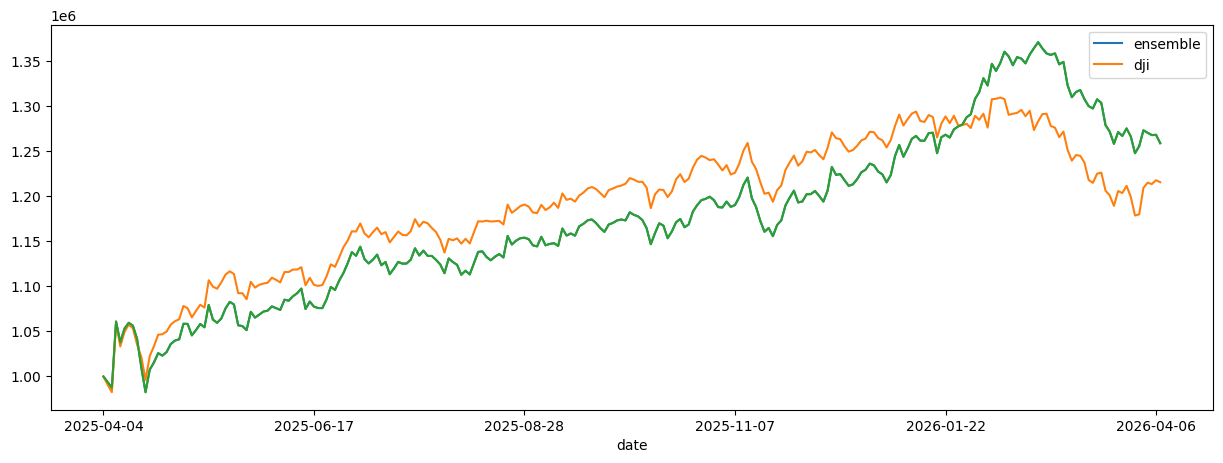

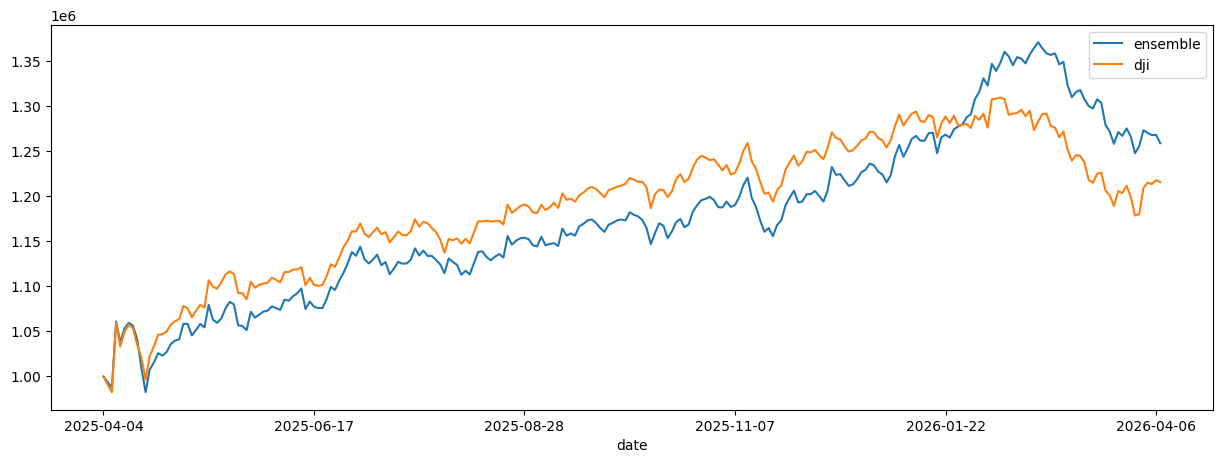

In [ ]:
print("==============Compare to DJIA===========")
result = audit_result.comparison
if result is not None:
    display(result.head())
    result.plot(figsize=(15, 5))
else:
    print("No baseline comparison was generated.")
